In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"

db_path = "data/data.db"

In [2]:
# Parameters
ticker = "NVDA"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

# Load the selected stock from the cleaned database
with sqlite3.connect(db_path) as conn:
    stock = pd.read_sql_query(
        """
        SELECT *
        FROM ohlc_hw_cleaned
        WHERE ticker = ?
          AND ts BETWEEN ? AND ?
        ORDER BY ts
        """,
        conn,
        params=(ticker, start_date, end_date)
    )

stock["ts"] = pd.to_datetime(stock["ts"])

print(
    f"{ticker} from {start_date} to {end_date}: "
    f"{len(stock)} trading days"
)

print("\nFirst observations:")
display(stock.head())

print("\nLast observations:")
display(stock.tail())

if not stock.empty:
    print("\nActual first date:", stock["ts"].min().date())
    print("Actual last date:", stock["ts"].max().date())

NVDA from 2024-06-01 to 2024-11-30: 97 trading days

First observations:


,ts,open,high,low,close,adj_close,volume,ticker,ticker_original,repair_flag,quarantine_reason,return_outlier,zero_volume_flag
0,2024-06-03,113.62,115.00,112.00,115.00,114.98,438392000,NVDA,"<a target=""_blank""><span style=""font-weight: b...",none,,0,0
1,2024-06-04,115.72,116.60,114.05,116.44,116.42,403324010,NVDA,NVDA,none,,0,0
2,2024-06-05,118.37,122.45,117.47,122.44,122.42,528402000,NVDA,NVDA,none,,0,0
3,2024-06-06,124.05,125.59,118.32,121.00,120.98,664696190,NVDA,NVDA,none,,0,0
4,2024-06-07,119.77,121.69,118.02,120.89,120.87,412386000,NVDA,NVDA,none,,0,0



Last observations:


,ts,open,high,low,close,adj_close,volume,ticker,ticker_original,repair_flag,quarantine_reason,return_outlier,zero_volume_flag
92,2024-10-14,136.470,139.60,136.30,138.07,138.07,232347700,NVDA,"<a target=""_blank""><span style=""font-weight: b...",none,,0,0
93,2024-10-15,137.870,138.57,128.74,131.60,131.60,377831021,NVDA,"<a target=""_blank""><span style=""font-weight: b...",none,,0,0
94,2024-10-16,133.980,136.62,131.58,135.72,135.72,264879720,NVDA,NVDA,none,,0,0
95,2024-10-17,139.340,140.89,136.87,136.93,136.93,306435921,NVDA,NVDA,none,,0,0
96,2024-10-18,138.665,138.90,137.28,138.00,138.00,169234338,NVDA,NVDA,none,,0,0



Actual first date: 2024-06-03
Actual last date: 2024-10-18


## 2.1–2.2 Parameters and Data Loading

I created a parameterized notebook that allows the user to select a stock ticker and analysis date range. The parameters can be changed to generate reports for different stocks.

I then loaded the selected stock's observations from the cleaned `ohlc_hw_cleaned` SQLite table, sorted them chronologically, and displayed the first and last observations along with the actual available date range.

# 2.3

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility."""
    return returns.rolling(window=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Calculate drawdown from the running maximum price."""
    running_max = prices.cummax()
    return (prices - running_max) / running_max


def calculate_sharpe_ratio(
    returns: pd.Series,
    risk_free_rate: float = 0.02
) -> float:
    """Calculate the annualized Sharpe ratio."""
    returns = returns.dropna()

    if len(returns) < 2 or returns.std(ddof=1) == 0:
        return np.nan

    return (
        returns.mean() * 252 - risk_free_rate
    ) / (returns.std(ddof=1) * np.sqrt(252))

In [5]:
if stock.empty:
    raise ValueError(f"No data found for {ticker} in the selected date range.")

if len(stock) < 21:
    raise ValueError("At least 21 prices are needed for 20 daily returns.")

stock = stock.sort_values("ts").reset_index(drop=True)

# Use adjusted closing prices
prices = stock["adj_close"]

# Calculate risk metrics
stock["log_return"] = calculate_returns(prices)
stock["rolling_volatility"] = calculate_volatility(stock["log_return"])
stock["drawdown"] = calculate_max_drawdown(prices)

sharpe_ratio = calculate_sharpe_ratio(stock["log_return"])
max_drawdown = stock["drawdown"].min()

print("Sharpe Ratio:", round(sharpe_ratio, 4))
print("Maximum Drawdown:", f"{max_drawdown:.2%}")

display(
    stock[
        ["ts", "adj_close", "log_return",
         "rolling_volatility", "drawdown"]
    ].head(25)
)

Sharpe Ratio: 0.7794
Maximum Drawdown: -27.05%


,ts,adj_close,log_return,rolling_volatility,drawdown
0,2024-06-03,114.98,NaN,NaN,0.000000
1,2024-06-04,116.42,0.012446,NaN,0.000000
2,2024-06-05,122.42,0.050253,NaN,0.000000
3,2024-06-06,120.98,-0.011833,NaN,-0.011763
4,2024-06-07,120.87,-0.000910,NaN,-0.012661
5,2024-06-10,121.77,0.007418,NaN,-0.005310
6,2024-06-11,120.90,-0.007170,NaN,-0.012416
7,2024-06-12,125.19,0.034869,NaN,0.000000
8,2024-06-13,129.60,0.034620,NaN,0.000000
9,2024-06-14,131.87,0.017364,NaN,0.000000


## 2.3 Risk Metrics

I calculated daily logarithmic returns using adjusted closing prices to account for stock splits and dividends.

I calculated 20-day rolling volatility using the sample standard deviation of daily log returns, annualized by multiplying by the square root of 252 trading days.

Drawdown measures the percentage decline from the highest adjusted closing price observed up to each date. The maximum drawdown is the lowest value in the drawdown series.

Finally, I calculated the annualized Sharpe ratio using a 2% annual risk-free rate. This measures risk-adjusted returns relative to the volatility of the stock.

# 2.4

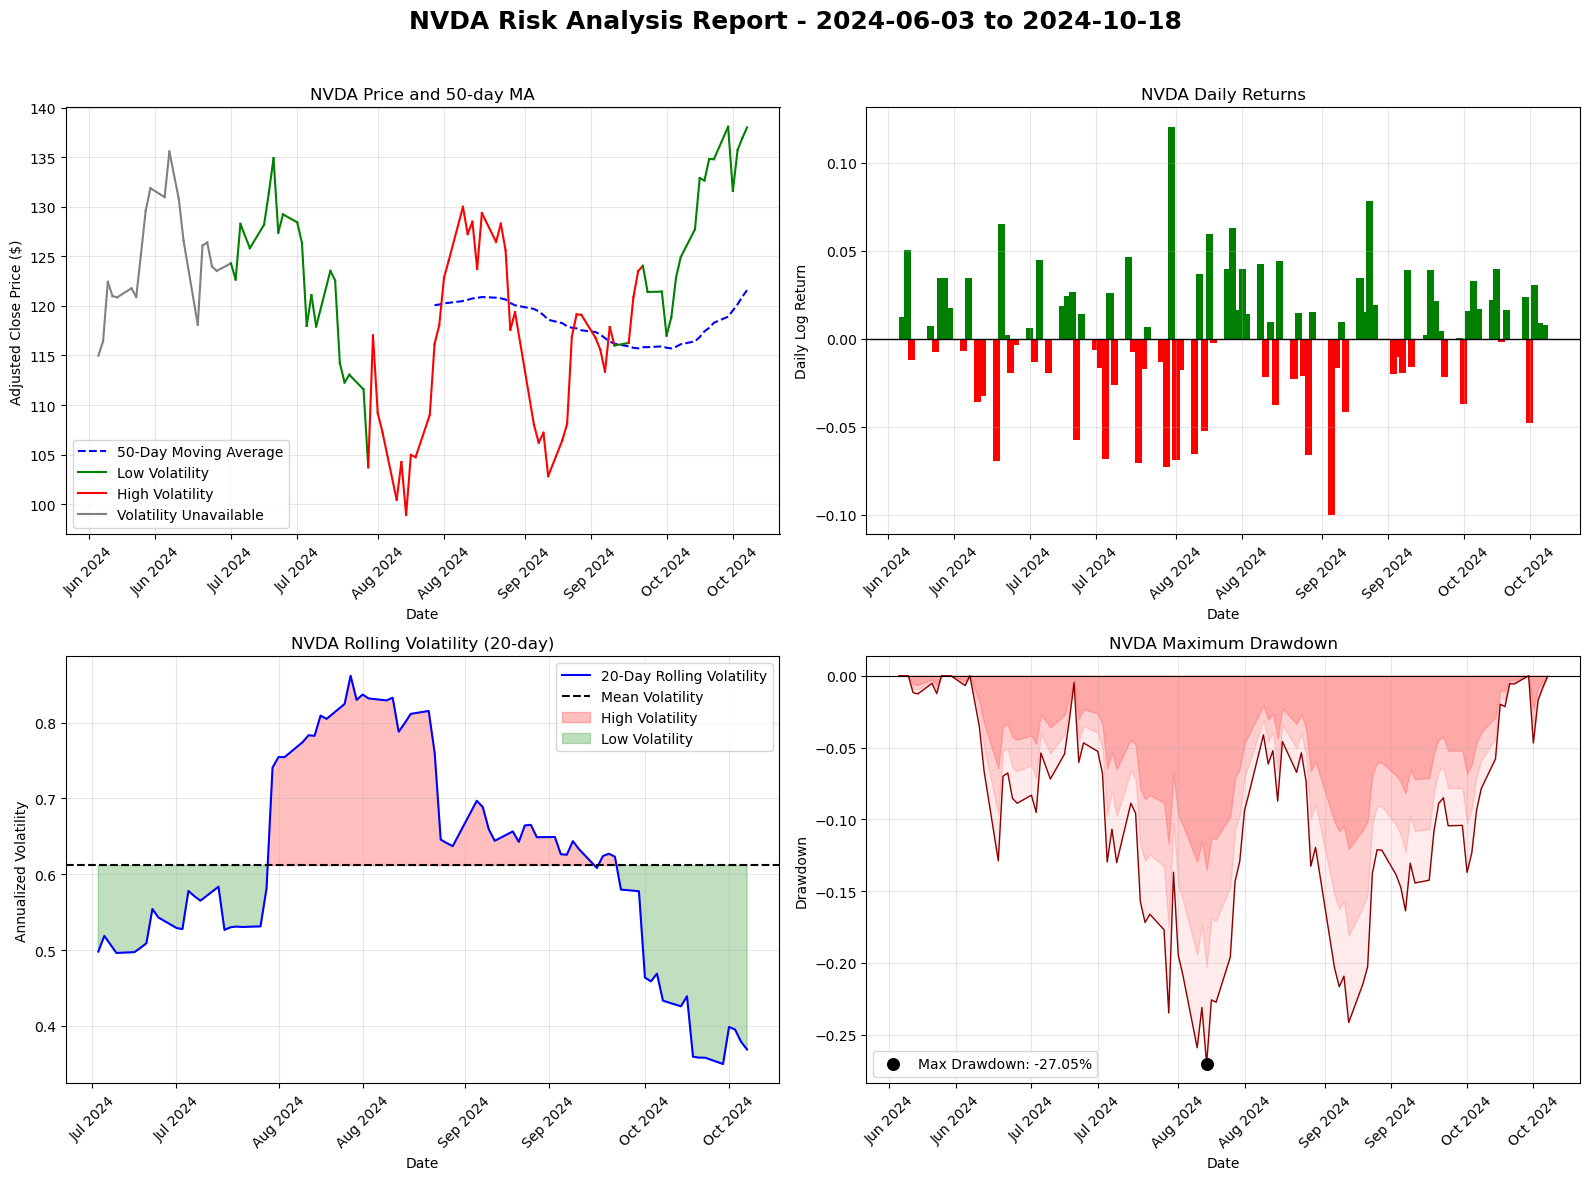

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# Calculate the 50-day moving average
stock["ma_50"] = stock["adj_close"].rolling(window=50).mean()

# Calculate average rolling volatility
mean_volatility = stock["rolling_volatility"].mean()

# Set up the 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

dates = stock["ts"]

# --------------------------------------------------
# TOP LEFT: Price Chart and 50-Day Moving Average
# --------------------------------------------------
ax = axes[0, 0]

ax.plot(
    dates, stock["ma_50"],
    color="blue", linestyle="--",
    label="50-Day Moving Average"
)

# Color the price line according to volatility
for i in range(1, len(stock)):
    vol = stock["rolling_volatility"].iloc[i]

    if pd.isna(vol) or pd.isna(mean_volatility):
        color = "gray"
    elif vol > mean_volatility:
        color = "red"
    else:
        color = "green"

    ax.plot(
        dates.iloc[i-1:i+1],
        stock["adj_close"].iloc[i-1:i+1],
        color=color,
        linewidth=1.5
    )

ax.plot([], [], color="green", label="Low Volatility")
ax.plot([], [], color="red", label="High Volatility")
ax.plot([], [], color="gray", label="Volatility Unavailable")

ax.set_title(f"{ticker} Price and 50-day MA")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Close Price ($)")
ax.legend()
ax.grid(True, alpha=0.3)


# --------------------------------------------------
# TOP RIGHT: Daily Log Returns
# --------------------------------------------------
ax = axes[0, 1]

return_colors = np.where(
    stock["log_return"] >= 0,
    "green",
    "red"
)

ax.bar(
    dates,
    stock["log_return"],
    color=return_colors,
    width=1.5
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(f"{ticker} Daily Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Log Return")
ax.grid(True, alpha=0.3)


# --------------------------------------------------
# BOTTOM LEFT: 20-Day Rolling Volatility
# --------------------------------------------------
ax = axes[1, 0]

ax.plot(
    dates,
    stock["rolling_volatility"],
    color="blue",
    label="20-Day Rolling Volatility"
)

ax.axhline(
    mean_volatility,
    color="black",
    linestyle="--",
    label="Mean Volatility"
)

# Shade high- and low-volatility regions
ax.fill_between(
    dates,
    stock["rolling_volatility"],
    mean_volatility,
    where=stock["rolling_volatility"] > mean_volatility,
    color="red",
    alpha=0.25,
    interpolate=True,
    label="High Volatility"
)

ax.fill_between(
    dates,
    stock["rolling_volatility"],
    mean_volatility,
    where=stock["rolling_volatility"] < mean_volatility,
    color="green",
    alpha=0.25,
    interpolate=True,
    label="Low Volatility"
)

ax.set_title(f"{ticker} Rolling Volatility (20-day)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Volatility")
ax.legend()
ax.grid(True, alpha=0.3)


# --------------------------------------------------
# BOTTOM RIGHT: Drawdown
# --------------------------------------------------
ax = axes[1, 1]

ax.plot(
    dates,
    stock["drawdown"],
    color="darkred",
    linewidth=1
)

# Layer transparent fills for a red gradient effect
for alpha, scale in [(0.08, 1.0), (0.12, 0.75), (0.18, 0.5)]:
    ax.fill_between(
        dates,
        stock["drawdown"] * scale,
        0,
        color="red",
        alpha=alpha
    )

# Mark the maximum drawdown
min_idx = stock["drawdown"].idxmin()

ax.scatter(
    stock.loc[min_idx, "ts"],
    stock.loc[min_idx, "drawdown"],
    color="black",
    s=70,
    zorder=5,
    label=f"Max Drawdown: {max_drawdown:.2%}"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(f"{ticker} Maximum Drawdown")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend()
ax.grid(True, alpha=0.3)


# --------------------------------------------------
# FINAL FORMATTING
# --------------------------------------------------
# Format the x-axis dates on all four graphs
for ax in axes.flat:
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %Y")
    )
    ax.tick_params(axis="x", rotation=45)

# Get the actual start and end dates from the stock data
actual_start = stock["ts"].min().strftime("%Y-%m-%d")
actual_end = stock["ts"].max().strftime("%Y-%m-%d")

# Add the updated chart title
fig.suptitle(
    f"{ticker} Risk Analysis Report - {actual_start} to {actual_end}",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 2.5

In [7]:
# Use adjusted closing prices and daily log returns
prices = stock["adj_close"]
returns = stock["log_return"].dropna()

# Total return
total_return = prices.iloc[-1] / prices.iloc[0] - 1

# Annualized return (compounded using log returns)
annualized_return = np.exp(
    returns.sum() * 252 / len(returns)
) - 1

# Annualized volatility
annualized_volatility = returns.std(ddof=1) * np.sqrt(252)

# Sharpe ratio
sharpe_ratio = calculate_sharpe_ratio(returns)

# Maximum drawdown
max_drawdown = stock["drawdown"].min()

# Best and worst daily log returns
best_day = returns.max()
worst_day = returns.min()

# Percentage of days with positive returns
positive_days = (returns > 0).mean()

# Average positive and negative log returns
average_up_day = returns[returns > 0].mean()
average_down_day = returns[returns < 0].mean()

# Create summary table
summary_df = pd.DataFrame({
    "Metric": [
        "Total Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown",
        "Best Day",
        "Worst Day",
        "Positive Days",
        "Average Up Day",
        "Average Down Day"
    ],
    "Value": [
        total_return,
        annualized_return,
        annualized_volatility,
        sharpe_ratio,
        max_drawdown,
        best_day,
        worst_day,
        positive_days,
        average_up_day,
        average_down_day
    ]
})

# Format values for display
summary_display = summary_df.copy()

summary_display["Value"] = [
    f"{value:.2f}" if metric == "Sharpe Ratio"
    else f"{value:+.2%}" if metric in [
        "Total Return", "Annualized Return",
        "Best Day", "Worst Day",
        "Average Up Day", "Average Down Day"
    ]
    else f"{value:.2%}"
    for metric, value in zip(
        summary_df["Metric"],
        summary_df["Value"]
    )
]

print(f"{ticker} Summary Statistics")
display(summary_display)

NVDA Summary Statistics


,Metric,Value
0,Total Return,+20.02%
1,Annualized Return,+61.45%
2,Annualized Volatility,58.90%
3,Sharpe Ratio,0.78
4,Maximum Drawdown,-27.05%
5,Best Day,+12.06%
6,Worst Day,-10.01%
7,Positive Days,54.17%
8,Average Up Day,+2.82%
9,Average Down Day,-2.92%


## Summary Statistics

I calculated ten summary statistics to evaluate the stock's performance and risk over the selected analysis period.  Total return measures the percentage change between the first and last adjusted closing prices. Annualized return estimates the compounded yearly return using daily logarithmic returns and 252 trading days per year.  Annualized volatility measures the variability of daily returns, while the Sharpe ratio measures risk-adjusted performance using a 2% annual risk-free rate.  Maximum drawdown measures the largest percentage decline from a previous price peak. The best and worst days identify the highest and lowest daily logarithmic returns.  Finally, I calculated the percentage of days with positive returns and the average returns on positive and negative trading days.  Together, these statistics provide a standardized summary of stock performance, volatility, and downside risk.

In [8]:
# Store numerical results for automated reporting
report_metrics = {
    "ticker": ticker,
    "avg_daily_return": returns.mean(),
    "avg_volatility": stock["rolling_volatility"].mean(),
    "max_drawdown": max_drawdown,
    "sharpe_ratio": sharpe_ratio,
    "total_return": total_return
}

print("Report metrics prepared for Part 3:")
print(report_metrics)

Report metrics prepared for Part 3:
{'ticker': 'NVDA', 'avg_daily_return': 0.0019009946350214697, 'avg_volatility': 0.6116397242899223, 'max_drawdown': -0.2704875709965331, 'sharpe_ratio': 0.7793954557869439, 'total_return': 0.20020873195338318}


In [9]:
import scrapbook as sb

sb.glue("report_metrics", report_metrics)